# Mini Project 15 — Running Project Keyword Spotting Embedded

**Anggota Kelompok:**
1. Christama Ezra Yudianto (245150307111009)
2. Abdillah Fatah Suryanto (245150300111008)
3. Ivang Arfandia (245150307111003)
4. Jahzeel Erason Nicodemus (245150300111002)

Notebook ini dibangkitkan dari `mini_project_15.py` (bagian wajib) dan `features/mp15_extension_quantization_analysis.py` (FITUR TAMBAHAN) lalu dieksekusi dari root folder mini project.

# Mini Project 15 — Kuantisasi, Verifikasi, dan Pembekuan Paket Deployment
Dua kandidat beku (klasik MP11 & Tiny CNN MP12) dikuantisasi ke INT8 (kalibrasi **training-only**),
diverifikasi kesetaraannya terhadap model float, dibenchmark (host reference), lalu **satu model utama dipilih**
dengan policy buku (dalam toleransi 0,03 macro-F1 frozen-test MP13 → payload terkecil → p95 latency terendah).
Tidak ada retraining / post-test tuning. Status -> `ready_for_mp16`.

**Adaptasi family-aware (penting):** kode buku mengasumsikan model klasik = *linear SVM* (`svm.coef_`).
Pada running project ini MP11 memilih **decision tree max_depth=2** (validasi F1 1,0; ops terkecil),
sehingga skrip ini memilih jalur kuantisasi sesuai family:
* family linear (`coef_` ada) → jalur buku apa adanya: bobot INT8 per-kelas + skala input per-tensor → nama `classical_svm_int8`.
* family tree (`tree_` ada) → **jalur tree INT8**: input dikuantisasi dengan skala input per-tensor yang sama (training-only),
  threshold tiap node dipetakan ke domain integer `t_q = floor(t / x_scale)` sehingga perbandingan `z <= t` menjadi
  `z_q <= t_q` (murni integer), daun menyimpan indeks kelas → nama `classical_tree_int8`.
Header C memuat fungsi inferensi `static inline` agar langsung dipakai MP16.
Adaptasi lain: `torch.load(..., weights_only=False)` eksplisit (PyTorch 2.6), ROOT otomatis, status rerun idempoten.

In [1]:
# Anggota Kelompok :
# 1. Christama Ezra Yudianto    (245150307111009)
# 2. Abdillah Fatah Suryanto    (245150300111008)
# 3. Ivang Arfandia             (245150307111003)
# 4. Jahzeel Erason Nicodemus   (245150300111002)
from pathlib import Path
import json, time, warnings
import numpy as np
import matplotlib
if "__file__" in globals():
    matplotlib.use("Agg")
import matplotlib.pyplot as plt
import joblib
import torch
import torch.nn as nn

ROOT = Path(__file__).resolve().parent if "__file__" in globals() else Path.cwd()
SEED = 2026
PERF_TOL = 0.03
TARGET_FRAMES = 96
BENCH_ITERS = 120
np.random.seed(SEED)
torch.manual_seed(SEED)
torch.set_num_threads(1)
warnings.filterwarnings('ignore', category=DeprecationWarning)
warnings.filterwarnings('ignore', category=UserWarning)


def save_json(path, obj):
    path.parent.mkdir(parents=True, exist_ok=True)
    path.write_text(json.dumps(obj, indent=2), encoding='utf-8')


def load_logmel(sample_id, mu, sigma):
    d = np.load(ROOT/'features/logmel/mp09'/f'{sample_id}.npz', allow_pickle=True)
    x = d['log_mel'].astype(np.float32)
    if x.shape[0] >= TARGET_FRAMES:
        x = x[:TARGET_FRAMES]
    else:
        fill = float(np.min(x)) if x.size else 0.0
        x = np.pad(x, ((0, TARGET_FRAMES-x.shape[0]), (0, 0)), constant_values=fill)
    return (x - mu) / sigma


def bench(fn, warmup=20, iters=BENCH_ITERS):
    for _ in range(warmup): fn()
    vals = []
    for _ in range(iters):
        t0 = time.perf_counter_ns(); fn(); vals.append((time.perf_counter_ns()-t0)/1e6)
    return {'mean_ms': float(np.mean(vals)), 'p95_ms': float(np.percentile(vals, 95)), 'min_ms': float(np.min(vals))}

## Gate: status, larangan post-test tuning, kontrak MP14

In [2]:
status_path = ROOT/'project_status.json'
status = json.loads(status_path.read_text(encoding='utf-8'))
if status.get('status') not in ('ready_for_mp15', 'ready_for_mp16'):
    raise RuntimeError(f"Status harus ready_for_mp15, ditemukan {status.get('status')!r}")

mp13 = json.loads((ROOT/'results/metrics/mp13_final_test_metrics.json').read_text(encoding='utf-8'))
rt = json.loads((ROOT/'config/realtime_architecture_config.json').read_text(encoding='utf-8'))
red = json.loads((ROOT/'config/feature_reduction_config.json').read_text(encoding='utf-8'))
clf_cfg = json.loads((ROOT/'config/classifier_config.json').read_text(encoding='utf-8'))
dl_cfg = json.loads((ROOT/'config/deep_learning_config.json').read_text(encoding='utf-8'))
split = json.loads((ROOT/'splits/mp09_split.json').read_text(encoding='utf-8'))

if mp13.get('post_test_tuning_performed'):
    raise RuntimeError('MP13 menunjukkan post-test tuning. Deployment dihentikan.')
if rt.get('final_model_selection') != 'DEFERRED_TO_MP15':
    raise RuntimeError('MP14 tidak menyerahkan pemilihan model ke MP15.')

classes = list(clf_cfg['classes'])
family = clf_cfg['chosen_family']
print('Gate OK | classical family =', family, '| classes =', classes)

Gate OK | classical family = tree | classes = ['mati', 'naik', 'nyala', 'turun']


## A. Model klasik float → INT8 (jalur sesuai family)

In [3]:
clf = joblib.load(ROOT/clf_cfg['model_file'])
D39 = np.load(ROOT/'features/dataset/mp09_features_39d.npz', allow_pickle=True)
X39 = D39['X'].astype(np.float64)
y = D39['y'].astype(str)
train_mask = D39['train_mask'].astype(bool)
test_mask = D39['test_mask'].astype(bool)
sel = np.asarray(red['selected_indices'], dtype=np.int64)
mean39 = np.asarray(red['scaler_mean'], dtype=np.float64)
scale39 = np.asarray(red['scaler_scale'], dtype=np.float64)
Z8 = ((X39 - mean39) / scale39)[:, sel]
float_pred = clf.predict(Z8).astype(str)

# Input scale dihitung tanpa tuning test. Input calibration = training only (sama untuk semua family).
train_max = float(np.max(np.abs(Z8[train_mask])))
x_scale = max(train_max / 127.0, 1e-8)


def quantize_input(z):
    return np.clip(np.round(np.asarray(z) / x_scale), -127, 127).astype(np.int8)


if hasattr(clf, 'coef_'):                                   # ---- jalur buku: linear SVM / logreg
    classical_kind = 'linear'
    classical_name = 'classical_svm_int8' if 'svm' in family else f'classical_{family}_int8'
    W = np.asarray(clf.coef_, dtype=np.float64)
    b = np.asarray(clf.intercept_, dtype=np.float64)
    W_scales = np.maximum(np.max(np.abs(W), axis=1) / 127.0, 1e-8)
    Wq = np.clip(np.round(W / W_scales[:, None]), -127, 127).astype(np.int8)

    def classical_int8_predict_idx(z):
        acc = Wq.astype(np.int32) @ quantize_input(z).astype(np.int32)
        return int(np.argmax(acc.astype(np.float64) * (W_scales * x_scale) + b))
    classical_params = {'weight_q': Wq, 'weight_scales': W_scales.astype(np.float32), 'bias': b.astype(np.float32)}
    classical_payload_bytes = int(Wq.size + 4*len(W_scales) + 4*len(b) + 4*len(sel)*3 + 4)
elif hasattr(clf, 'tree_'):                                 # ---- jalur tree INT8 (adaptasi)
    classical_kind = 'tree'
    classical_name = f'classical_{family}_int8'
    tr = clf.tree_
    is_leaf = tr.children_left == -1
    t_feat = np.where(is_leaf, -1, tr.feature).astype(np.int8)
    t_thr_q = np.where(is_leaf, 0, np.clip(np.floor(tr.threshold / x_scale), -128, 127)).astype(np.int8)
    t_left = tr.children_left.astype(np.int16); t_right = tr.children_right.astype(np.int16)
    clf_cls = [str(c) for c in clf.classes_]
    t_leaf_cls = np.array([classes.index(clf_cls[int(np.argmax(tr.value[i, 0]))]) if is_leaf[i] else 255
                           for i in range(tr.node_count)], dtype=np.uint8)

    def classical_int8_predict_idx(z):
        zq = quantize_input(z).astype(np.int32); n = 0
        while t_feat[n] >= 0:
            n = t_left[n] if zq[t_feat[n]] <= int(t_thr_q[n]) else t_right[n]
        return int(t_leaf_cls[n])
    classical_params = {'tree_feature': t_feat, 'tree_threshold_q': t_thr_q, 'tree_left': t_left, 'tree_right': t_right,
                        'tree_leaf_class': t_leaf_cls, 'tree_threshold_float': tr.threshold.astype(np.float32)}
    classical_payload_bytes = int(tr.node_count*(1+1+2+2+1) + 4*len(sel)*2 + len(sel)*4 + 4)
else:
    raise RuntimeError(f'Family {family!r} belum didukung jalur INT8')

q_pred = np.asarray([classes[classical_int8_predict_idx(z)] for z in Z8])
cls_agree_all = float(np.mean(q_pred == float_pred))
cls_agree_test = float(np.mean(q_pred[test_mask] == float_pred[test_mask]))
print(f'{classical_name}: x_scale={x_scale:.6g} | agreement all={cls_agree_all:.3f} test={cls_agree_test:.3f} | payload={classical_payload_bytes} B')
if classical_kind == 'tree':
    for i in range(tr.node_count):
        if not is_leaf[i]:
            print(f'  node {i}: z[{t_feat[i]}] <= {tr.threshold[i]:+.5f}  ->  z_q[{t_feat[i]}] <= {int(t_thr_q[i])}  (x_scale={x_scale:.5f})')

# Export package.
model_dir = ROOT/'models'; model_dir.mkdir(parents=True, exist_ok=True)
firmware_dir = ROOT/'firmware'; firmware_dir.mkdir(parents=True, exist_ok=True)
np.savez_compressed(model_dir/'mp15_classical_int8.npz',
                    kind=np.asarray(classical_kind), family=np.asarray(family),
                    selected_indices=sel.astype(np.int32),
                    selected_mean=mean39[sel].astype(np.float32),
                    selected_scale=scale39[sel].astype(np.float32),
                    input_quant_scale=np.asarray([x_scale], dtype=np.float32),
                    classes=np.asarray(classes, dtype=object), **classical_params)

classical_tree_int8: x_scale=0.0151334 | agreement all=1.000 test=1.000 | payload=149 B
  node 0: z[2] <= +0.04497  ->  z_q[2] <= 2  (x_scale=0.01513)
  node 1: z[7] <= -0.39102  ->  z_q[7] <= -26  (x_scale=0.01513)
  node 4: z[7] <= +0.07045  ->  z_q[7] <= 4  (x_scale=0.01513)


### Header C model klasik INT8 (+ fungsi inferensi inline untuk MP16)

In [4]:
def cf(v):
    """Literal float C yang selalu valid (mis. 4200 -> 4200.0f, bukan 4200f)."""
    t = f'{float(v):.9g}'
    return (t if any(ch in t for ch in '.eEn') else t + '.0') + 'f'


def c_arr(name, arr, ctype, fmt):
    flat = np.asarray(arr).reshape(-1)
    vals = ', '.join(fmt(v) for v in flat)
    return f'static const {ctype} {name}[{len(flat)}] = {{{vals}}};\n'


h = []
h.append('// Auto-generated by Mini Project 15. Frozen deployment package.\n#pragma once\n#include <stdint.h>\n#include <math.h>\n')
h.append(f'// family: {family} ({classical_kind}) | model: {classical_name}\n')
h.append(f'#define MP15_INPUT_DIM {len(sel)}\n#define MP15_N_CLASSES {len(classes)}\n')
h.append(c_arr('MP15_FEATURE_INDEX', sel, 'int32_t', lambda v: str(int(v))))
h.append(c_arr('MP15_FEATURE_MEAN', mean39[sel], 'float', cf))
h.append(c_arr('MP15_FEATURE_SCALE', scale39[sel], 'float', cf))
h.append(f'static const float MP15_INPUT_Q_SCALE = {cf(x_scale)};\n')
h.append('''static inline void mp15_quantize_input(const float *x39, int8_t *zq) {
    for (int i = 0; i < MP15_INPUT_DIM; ++i) {
        float z = (x39[MP15_FEATURE_INDEX[i]] - MP15_FEATURE_MEAN[i]) / MP15_FEATURE_SCALE[i];
        float q = roundf(z / MP15_INPUT_Q_SCALE);
        zq[i] = (int8_t)(q > 127.f ? 127 : (q < -127.f ? -127 : q));
    }
}
''')
if classical_kind == 'linear':
    h.append(c_arr('MP15_WEIGHT_Q', Wq, 'int8_t', lambda v: str(int(v))))
    h.append(c_arr('MP15_WEIGHT_SCALE', W_scales, 'float', cf))
    h.append(c_arr('MP15_BIAS', b, 'float', cf))
    h.append('''/* Return indeks kelas; input = vektor 39-D mentah (belum di-scale). */
static inline int mp15_classical_predict(const float *x39) {
    int8_t zq[MP15_INPUT_DIM]; mp15_quantize_input(x39, zq);
    int best = 0; float best_s = -1e30f;
    for (int c = 0; c < MP15_N_CLASSES; ++c) {
        int32_t acc = 0;
        for (int i = 0; i < MP15_INPUT_DIM; ++i) acc += (int32_t)MP15_WEIGHT_Q[c*MP15_INPUT_DIM+i] * (int32_t)zq[i];
        float s = (float)acc * MP15_WEIGHT_SCALE[c] * MP15_INPUT_Q_SCALE + MP15_BIAS[c];
        if (s > best_s) { best_s = s; best = c; }
    }
    return best;
}
''')
else:
    h.append(f'#define MP15_TREE_N_NODES {tr.node_count}\n')
    h.append(c_arr('MP15_TREE_FEATURE', t_feat, 'int8_t', lambda v: str(int(v))))
    h.append(c_arr('MP15_TREE_THRESH_Q', t_thr_q, 'int8_t', lambda v: str(int(v))))
    h.append(c_arr('MP15_TREE_LEFT', t_left, 'int16_t', lambda v: str(int(v))))
    h.append(c_arr('MP15_TREE_RIGHT', t_right, 'int16_t', lambda v: str(int(v))))
    h.append(c_arr('MP15_TREE_LEAF_CLASS', t_leaf_cls, 'uint8_t', lambda v: str(int(v))))
    h.append('''/* Return indeks kelas; input = vektor 39-D mentah. Inferensi murni integer setelah kuantisasi input. */
static inline int mp15_classical_predict(const float *x39) {
    int8_t zq[MP15_INPUT_DIM]; mp15_quantize_input(x39, zq);
    int n = 0;
    while (MP15_TREE_FEATURE[n] >= 0)
        n = (zq[MP15_TREE_FEATURE[n]] <= MP15_TREE_THRESH_Q[n]) ? MP15_TREE_LEFT[n] : MP15_TREE_RIGHT[n];
    return (int)MP15_TREE_LEAF_CLASS[n];
}
''')
for i, c in enumerate(classes): h.append(f'// class {i}: {c}\n')
(firmware_dir/'mp15_classical_model_int8.h').write_text(''.join(h), encoding='utf-8')
print('Header ditulis: firmware/mp15_classical_model_int8.h')

Header ditulis: firmware/mp15_classical_model_int8.h


## B. Tiny CNN float → static INT8 PTQ (eager mode, kalibrasi training-only)

In [5]:
class FloatTinyKWS(nn.Module):
    def __init__(self, n_classes):
        super().__init__()
        self.features = nn.Sequential(
            nn.Conv2d(1, 8, 3, padding=1, bias=False), nn.BatchNorm2d(8), nn.ReLU(), nn.MaxPool2d(2),
            nn.Conv2d(8, 16, 3, padding=1, bias=False), nn.BatchNorm2d(16), nn.ReLU(), nn.AdaptiveAvgPool2d((1, 1)))
        self.classifier = nn.Linear(16, n_classes)

    def forward(self, x):
        return self.classifier(self.features(x).flatten(1))


class QuantTinyKWS(nn.Module):
    def __init__(self, n_classes):
        super().__init__()
        self.quant = torch.ao.quantization.QuantStub()
        self.conv1 = nn.Conv2d(1, 8, 3, padding=1, bias=False); self.bn1 = nn.BatchNorm2d(8); self.relu1 = nn.ReLU(); self.pool = nn.MaxPool2d(2)
        self.conv2 = nn.Conv2d(8, 16, 3, padding=1, bias=False); self.bn2 = nn.BatchNorm2d(16); self.relu2 = nn.ReLU(); self.gap = nn.AdaptiveAvgPool2d((1, 1))
        self.fc = nn.Linear(16, n_classes); self.dequant = torch.ao.quantization.DeQuantStub()

    def forward(self, x):
        x = self.quant(x); x = self.relu1(self.bn1(self.conv1(x))); x = self.pool(x); x = self.relu2(self.bn2(self.conv2(x)))
        x = self.gap(x); x = x.flatten(1); x = self.fc(x); return self.dequant(x)


ckpt = torch.load(ROOT/dl_cfg['model_file'], map_location='cpu', weights_only=False)
mu = float(ckpt['normalization']['mean']); sigma = float(ckpt['normalization']['std'])
float_net = FloatTinyKWS(len(classes)); float_net.load_state_dict(ckpt['state_dict']); float_net.eval()
qnet = QuantTinyKWS(len(classes))
mp = {
    'features.0.weight': 'conv1.weight', 'features.1.weight': 'bn1.weight', 'features.1.bias': 'bn1.bias', 'features.1.running_mean': 'bn1.running_mean',
    'features.1.running_var': 'bn1.running_var', 'features.1.num_batches_tracked': 'bn1.num_batches_tracked',
    'features.4.weight': 'conv2.weight', 'features.5.weight': 'bn2.weight', 'features.5.bias': 'bn2.bias', 'features.5.running_mean': 'bn2.running_mean',
    'features.5.running_var': 'bn2.running_var', 'features.5.num_batches_tracked': 'bn2.num_batches_tracked', 'classifier.weight': 'fc.weight', 'classifier.bias': 'fc.bias'}
qnet.load_state_dict({mp[k]: v for k, v in ckpt['state_dict'].items()}, strict=True); qnet.eval()
torch.ao.quantization.fuse_modules(qnet, [['conv1', 'bn1', 'relu1'], ['conv2', 'bn2', 'relu2']], inplace=True)
engine = 'fbgemm' if 'fbgemm' in torch.backends.quantized.supported_engines else torch.backends.quantized.supported_engines[0]
torch.backends.quantized.engine = engine
qnet.qconfig = torch.ao.quantization.get_default_qconfig(engine)
torch.ao.quantization.prepare(qnet, inplace=True)
# Calibration TRAINING ONLY.
with torch.no_grad():
    for sid in split['train_ids']:
        x = load_logmel(sid, mu, sigma)
        qnet(torch.from_numpy(x[None, None]).float())
torch.ao.quantization.convert(qnet, inplace=True); qnet.eval()

# Prediction agreement after quantization. This is equivalence checking, not retuning.
all_ids = list(split['train_ids'])+list(split['validation_ids'])+list(split['test_ids'])
float_cnn = []; quant_cnn = []
with torch.no_grad():
    for sid in all_ids:
        x = load_logmel(sid, mu, sigma); xt = torch.from_numpy(x[None, None]).float()
        float_cnn.append(classes[int(float_net(xt).argmax(1).item())])
        quant_cnn.append(classes[int(qnet(xt).argmax(1).item())])
float_cnn = np.asarray(float_cnn); quant_cnn = np.asarray(quant_cnn)
ntr = len(split['train_ids']); nv = len(split['validation_ids']); test_slice = slice(ntr+nv, len(all_ids))
cnn_agree_all = float(np.mean(float_cnn == quant_cnn)); cnn_agree_test = float(np.mean(float_cnn[test_slice] == quant_cnn[test_slice]))
changed = [(sid, f, q) for sid, f, q in zip(all_ids, float_cnn, quant_cnn) if f != q]
print(f'Tiny CNN INT8 ({engine}): agreement all={cnn_agree_all:.3f} test={cnn_agree_test:.3f} | label berubah: {changed}')

# TorchScript host artifact. Note: this is not a TFLM flatbuffer.
example = torch.randn(1, 1, TARGET_FRAMES, 26)
scripted = torch.jit.trace(qnet, example)
qcnn_path = model_dir/'mp15_tiny_cnn_int8_torchscript.pt'
torch.jit.save(scripted, str(qcnn_path))

Tiny CNN INT8 (fbgemm): agreement all=1.000 test=1.000 | label berubah: []


## C. Benchmark host reference + payload + kebijakan seleksi

In [6]:
ix0 = np.where(train_mask)[0][0]; z0 = Z8[ix0]
bench_cls_float = bench(lambda: clf.predict(z0.reshape(1, -1)), iters=300)
bench_cls_int8 = bench(lambda: classical_int8_predict_idx(z0), iters=300)
x0 = load_logmel(split['train_ids'][0], mu, sigma); xt0 = torch.from_numpy(x0[None, None]).float()
with torch.no_grad():
    bench_cnn_float = bench(lambda: float_net(xt0), iters=100)
    bench_cnn_int8 = bench(lambda: qnet(xt0), iters=100)

# Payload estimates, not runtime/library overhead.
dlmet = json.loads((ROOT/'results/metrics/mp12_deep_learning_metrics.json').read_text(encoding='utf-8'))
cnn_int8_weight_bytes = int(dlmet['estimated_int8_parameter_bytes'])

# Frozen-test performance from MP13. Selection policy: within PERF_TOL, smaller payload wins.
f1_class = float(mp13['classical']['macro_f1']); f1_cnn = float(mp13['tiny_cnn']['macro_f1'])
best_f1 = max(f1_class, f1_cnn)
choices = []
if f1_class >= best_f1-PERF_TOL: choices.append((classical_name, classical_payload_bytes, bench_cls_int8['p95_ms']))
if f1_cnn >= best_f1-PERF_TOL: choices.append(('tiny_cnn_int8', cnn_int8_weight_bytes, bench_cnn_int8['p95_ms']))
selected = sorted(choices, key=lambda x: (x[1], x[2]))[0][0]
selected_is_classical = selected.startswith('classical_')
print('Kandidat dalam toleransi:', choices)
print('Model deployment terpilih:', selected)

reason = []
if f1_class < best_f1-PERF_TOL: reason.append(f'classical di luar toleransi (F1 {f1_class:.3f} vs best {best_f1:.3f})')
if f1_cnn < best_f1-PERF_TOL: reason.append(f'tiny_cnn di luar toleransi (F1 {f1_cnn:.3f} vs best {best_f1:.3f})')
reason.append('dari kandidat dalam toleransi dipilih payload terkecil lalu p95 latency host terendah')

Kandidat dalam toleransi: [('classical_tree_int8', 149, 0.0079)]
Model deployment terpilih: classical_tree_int8


## D. deployment_config, laporan metrik, manifest MP16

In [7]:
config = {
    'source_status': 'ready_for_mp15',
    'post_test_tuning_performed': False,
    'cnn_ptq_calibration_scope': 'training_only',
    'svm_input_quant_calibration_scope': 'training_only',
    'classical_input_quant_calibration_scope': 'training_only',
    'classical_family': family,
    'classical_int8_kind': classical_kind,
    'selection_uses_frozen_mp13_metrics': True,
    'selection_policy': f'candidate within {PERF_TOL:.2f} macro-F1 of best -> smaller deployment payload -> lower reference p95 latency',
    'selected_deployment_model': selected,
    'primary_target_profile': 'MCU_first' if selected_is_classical else 'MPU_or_accelerated_MCU',
    'fallback_candidate': 'tiny_cnn_int8' if selected_is_classical else classical_name,
    'realtime_contract': 'config/realtime_architecture_config.json',
    'classical_package': 'models/mp15_classical_int8.npz',
    'classical_c_header': 'firmware/mp15_classical_model_int8.h',
    'tiny_cnn_host_quantized_package': 'models/mp15_tiny_cnn_int8_torchscript.pt',
    'note': 'TorchScript INT8 is used for host numerical/latency validation. MP16 ports the selected final model to the actual embedded runtime.'
}
save_json(ROOT/'config/deployment_config.json', config)

report = {
    'frozen_test_macro_f1': {'classical': f1_class, 'tiny_cnn': f1_cnn},
    'classical_int8': {
        'name': classical_name, 'family': family, 'kind': classical_kind,
        'agreement_all_24_vs_float': cls_agree_all,
        'agreement_test_vs_float': cls_agree_test,
        'input_quant_scale': x_scale,
        **({'weight_scales': W_scales.tolist()} if classical_kind == 'linear' else
           {'threshold_float': tr.threshold.tolist(), 'threshold_q': t_thr_q.tolist(), 'node_count': int(tr.node_count)}),
        'payload_bytes_estimate': classical_payload_bytes,
        'host_reference_latency': bench_cls_int8,
        'float_host_reference_latency': bench_cls_float
    },
    'tiny_cnn_int8': {
        'calibration_scope': 'training_only',
        'quantized_engine': engine,
        'agreement_all_24_vs_float': cnn_agree_all,
        'agreement_test_vs_float': cnn_agree_test,
        'changed_labels': [list(c) for c in changed],
        'weight_bytes_estimate': cnn_int8_weight_bytes,
        'torchscript_file_bytes': int(qcnn_path.stat().st_size),
        'host_reference_latency': bench_cnn_int8,
        'float_host_reference_latency': bench_cnn_float
    },
    'selection': {
        'performance_tolerance': PERF_TOL,
        'candidates_within_tolerance': [list(c) for c in choices],
        'selected_model': selected,
        'reason': '; '.join(reason)
    },
    'device_measurement_note': 'Host latency is not target-device latency. Actual latency, peak RAM, flash and power are measured during MP16 integration.',
    'post_test_tuning_performed': False
}
save_json(ROOT/'results/metrics/mp15_deployment_metrics.json', report)

# Manifest for MP16.
manifest = {
    'selected_model': selected,
    'classical_family': family,
    'classes': classes,
    'sample_rate_hz': rt['sample_rate_hz'],
    'dma_block_samples': rt['dma_block_samples'],
    'feature_frame_samples': rt['feature_frame_samples'],
    'feature_hop_samples': rt['feature_hop_samples'],
    'inference_stride_frames': rt['inference_stride_frames'],
    'selected_feature_names': red['selected_feature_names'] if selected_is_classical else None,
    'files_required': [
        'config/project_config.json', 'config/filter_final_config.json', 'config/preprocessing_config.json', 'config/feature_config.json',
        'config/realtime_architecture_config.json', 'config/deployment_config.json', 'firmware/mp14_realtime_constants.h',
        'firmware/mp15_classical_model_int8.h' if selected_is_classical else 'models/mp15_tiny_cnn_int8_torchscript.pt',
        'models/mp15_classical_int8.npz' if selected_is_classical else 'models/mp12_tiny_cnn_state.pt'
    ]
}
save_json(ROOT/'deployment/mp15_manifest.json', manifest)
missing = [f for f in manifest['files_required'] if not (ROOT/f).exists()]
print('File manifest yang hilang:', missing)
assert not missing

File manifest yang hilang: []


## E. Visualisasi: ukuran, latency host, kesetaraan

In [8]:
figdir = ROOT/'results/figures'; figdir.mkdir(parents=True, exist_ok=True)
cl = family.upper() if len(family) <= 4 else family
plt.figure(figsize=(7.2, 4.5))
names = [f'{cl} float\nserialized', f'{cl} INT8\npayload', 'CNN FP32\nweights', 'CNN INT8\nweights']
vals = [int(mp13['resource_proxy']['classical']['serialized_bytes']), classical_payload_bytes, int(dlmet['float32_parameter_bytes']), cnn_int8_weight_bytes]
plt.bar(names, vals); plt.ylabel('Byte'); plt.title('MP15 - Ukuran model/payload deployment'); plt.grid(axis='y', alpha=.2)
for i, v in enumerate(vals): plt.text(i, v, str(v), ha='center', va='bottom', fontsize=8)
plt.tight_layout(); plt.savefig(figdir/'mp15_model_size.png', dpi=170); plt.close()

plt.figure(figsize=(7.2, 4.5))
names = [f'{cl} float', f'{cl} INT8 ref', 'CNN float', 'CNN INT8']
vals = [bench_cls_float['p95_ms'], bench_cls_int8['p95_ms'], bench_cnn_float['p95_ms'], bench_cnn_int8['p95_ms']]
plt.bar(names, vals); plt.ylabel('p95 latency host (ms)'); plt.title('MP15 - Benchmark referensi host'); plt.grid(axis='y', alpha=.2); plt.tight_layout()
plt.savefig(figdir/'mp15_latency.png', dpi=170); plt.close()

plt.figure(figsize=(7.2, 4.5))
plt.bar([f'{cl} all', f'{cl} test', 'CNN all', 'CNN test'], [cls_agree_all, cls_agree_test, cnn_agree_all, cnn_agree_test]); plt.ylim(0, 1.05)
plt.ylabel('Prediction agreement'); plt.title('MP15 - Kesetaraan prediksi sebelum/sesudah kuantisasi'); plt.grid(axis='y', alpha=.2); plt.tight_layout()
plt.savefig(figdir/'mp15_equivalence.png', dpi=170); plt.close()

## F. Update status + checklist kelulusan

In [9]:
status['status'] = 'ready_for_mp16'; status['last_completed_mini_project'] = 15
done = set(status.get('completed_mini_projects', [])); done.add(15); status['completed_mini_projects'] = sorted(done)
status['mp15'] = {
    'deployment_config': 'config/deployment_config.json',
    'deployment_metrics': 'results/metrics/mp15_deployment_metrics.json',
    'deployment_manifest': 'deployment/mp15_manifest.json',
    'selected_model': selected,
    'classical_package': 'models/mp15_classical_int8.npz',
    'classical_header': 'firmware/mp15_classical_model_int8.h',
    'tiny_cnn_quantized_host_artifact': 'models/mp15_tiny_cnn_int8_torchscript.pt',
    'post_test_tuning_performed': False,
    'device_benchmark_deferred_to_mp16': True
}
save_json(status_path, status)

print('Mini Project 15 selesai.')
print(f'{classical_name} agreement all/test:', cls_agree_all, cls_agree_test)
print('CNN agreement all/test:', cnn_agree_all, cnn_agree_test)
print('Selected deployment model:', selected)
checks = [('Calibration CNN', 'training-only', config['cnn_ptq_calibration_scope']),
          ('Calibration input klasik', 'training-only', config['classical_input_quant_calibration_scope']),
          ('Post-test tuning', 'False', str(config['post_test_tuning_performed'])),
          ('Agreement klasik', 'ideal 1,00', f'{cls_agree_all:.2f} (test {cls_agree_test:.2f})'),
          ('Agreement CNN', 'ideal 1,00', f'{cnn_agree_all:.2f} (test {cnn_agree_test:.2f})'),
          ('C header', 'tersedia', str((firmware_dir/'mp15_classical_model_int8.h').exists())),
          ('Deployment manifest', 'tersedia', str((ROOT/'deployment/mp15_manifest.json').exists())),
          ('Model selection', 'tercatat + policy', selected),
          ('Status akhir', 'ready_for_mp16', status['status'])]
print(f"\n{'Pemeriksaan':26s} | {'Kriteria':18s} | Hasil")
for c in checks: print(f'{c[0]:26s} | {c[1]:18s} | {c[2]}')
print('Status:', status['status'])

Mini Project 15 selesai.
classical_tree_int8 agreement all/test: 1.0 1.0
CNN agreement all/test: 1.0 1.0
Selected deployment model: classical_tree_int8

Pemeriksaan                | Kriteria           | Hasil
Calibration CNN            | training-only      | training_only
Calibration input klasik   | training-only      | training_only
Post-test tuning           | False              | False
Agreement klasik           | ideal 1,00         | 1.00 (test 1.00)
Agreement CNN              | ideal 1,00         | 1.00 (test 1.00)
C header                   | tersedia           | True
Deployment manifest        | tersedia           | True
Model selection            | tercatat + policy  | classical_tree_int8
Status akhir               | ready_for_mp16     | ready_for_mp16
Status: ready_for_mp16


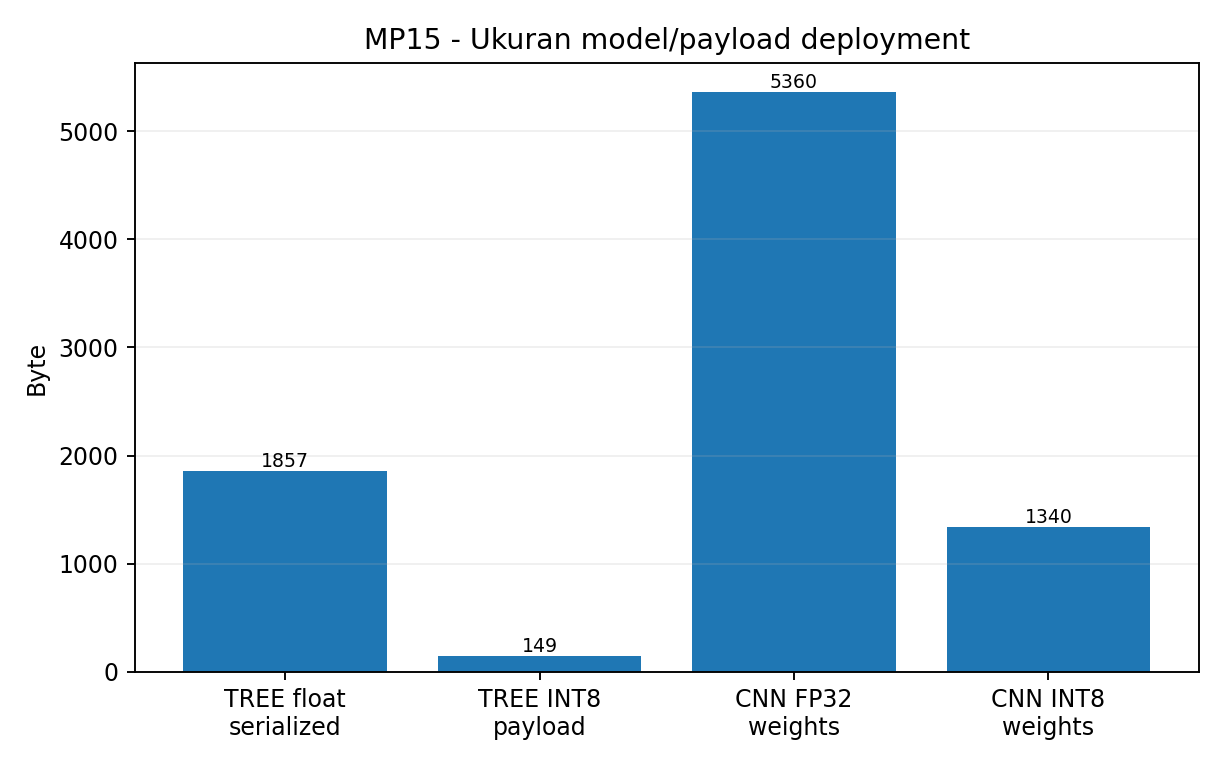

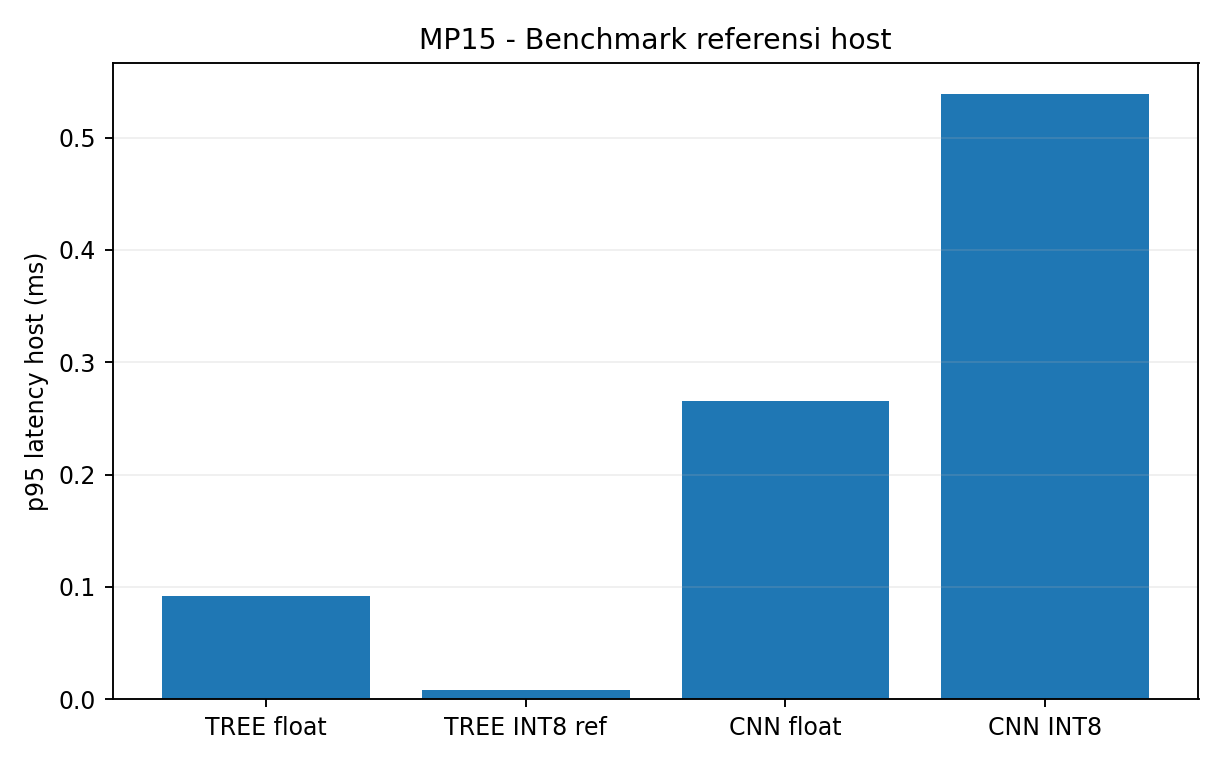

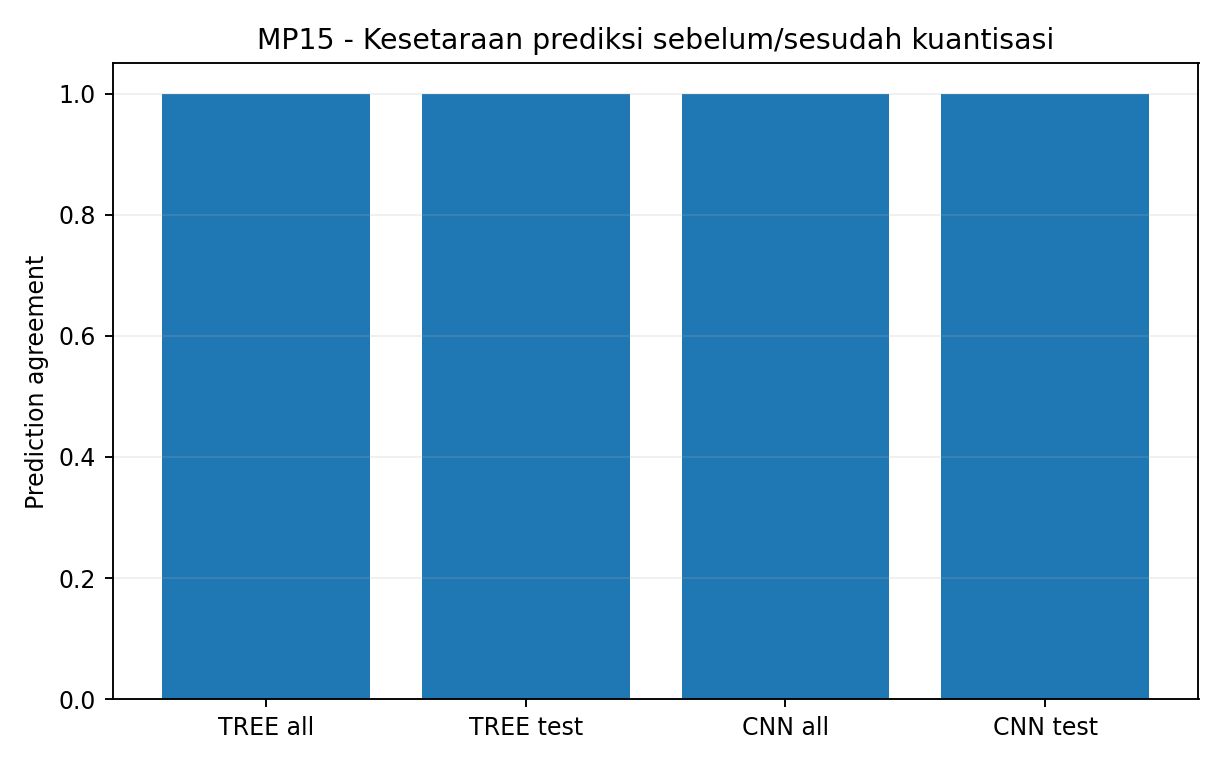

In [10]:
if "__file__" not in globals():
    from IPython.display import Image, display
    for p in ['mp15_model_size.png', 'mp15_latency.png', 'mp15_equivalence.png']:
        display(Image(filename=str(figdir/p), width=560))

---
# FITUR TAMBAHAN (di luar tugas wajib)
Sumber: `features/mp15_extension_quantization_analysis.py`

## FITUR TAMBAHAN MP15 — Verifikasi C INT8, Jalur SVM Buku, Bit-Width Sweep, Margin, Per-Channel vs Per-Tensor, FP16 & Paket ZIP
Modul mandiri setelah `mini_project_15.py`. **Model/scale terpilih tidak diubah** (artefak dibaca beku);
semua analisis bersifat verifikasi & dokumentasi (materi Bab 15: PTQ, symmetric/asymmetric, per-channel,
numeric equivalence, packaging reproducible).

1. **Equivalence test C vs Python**: header `mp15_classical_model_int8.h` dikompilasi `gcc` dan dijalankan pada 24 vektor 39-D.
2. **Jalur INT8 buku untuk linear SVM** (arsip MP11, hash diverifikasi) → header referensi + uji C — membuktikan kode buku tetap
   berjalan walau SVM bukan model terpilih.
3. **Bit-width sweep** 8→2 bit (tree & SVM), skala input *per-tensor* vs *per-feature*, diuji pada 24 sampel + 2000 sampel
   ter-jitter dari train (resolusi agreement lebih halus daripada 24 sampel).
4. **Margin keputusan tree** dalam satuan LSB (berapa jauh tiap sampel dari threshold setelah kuantisasi).
5. **CNN**: SQNR bobot per-tensor vs per-channel, SQNR logit INT8 vs float, FP16 (agreement & error).
6. **Footprint terkompilasi** (`size` pada object `-Os`) + **paket deployment** (salinan file manifest + SHA-256 + ZIP terverifikasi).

Anggota Kelompok : Christama Ezra Yudianto (245150307111009), Abdillah Fatah Suryanto (245150300111008),
Ivang Arfandia (245150307111003), Jahzeel Erason Nicodemus (245150300111002)

In [11]:
from pathlib import Path
import json, hashlib, shutil, subprocess, os, zipfile, warnings
import numpy as np
import matplotlib
if "__file__" in globals():
    matplotlib.use("Agg")
import matplotlib.pyplot as plt
import joblib
import torch
import torch.nn as nn

warnings.filterwarnings('ignore')
ROOT = Path(__file__).resolve().parent.parent if "__file__" in globals() else Path.cwd()
status = json.loads((ROOT/'project_status.json').read_text(encoding='utf-8'))
assert status['status'] in ('ready_for_mp16',), 'Jalankan mini_project_15.py terlebih dahulu'
dep = json.loads((ROOT/'config/deployment_config.json').read_text(encoding='utf-8'))
rep = json.loads((ROOT/'results/metrics/mp15_deployment_metrics.json').read_text(encoding='utf-8'))
manifest = json.loads((ROOT/'deployment/mp15_manifest.json').read_text(encoding='utf-8'))
red = json.loads((ROOT/'config/feature_reduction_config.json').read_text(encoding='utf-8'))
clf_cfg = json.loads((ROOT/'config/classifier_config.json').read_text(encoding='utf-8'))
split = json.loads((ROOT/'splits/mp09_split.json').read_text(encoding='utf-8'))
OUT_MET, OUT_FIG, FW = ROOT/'results/metrics', ROOT/'results/figures', ROOT/'firmware'
(FW/'build').mkdir(parents=True, exist_ok=True)
classes = list(clf_cfg['classes'])
D39 = np.load(ROOT/'features/dataset/mp09_features_39d.npz', allow_pickle=True)
X39 = D39['X'].astype(np.float64); train_mask = D39['train_mask'].astype(bool)
SEL = np.asarray(red['selected_indices'], int); MU = np.asarray(red['scaler_mean']); SC = np.asarray(red['scaler_scale'])
Z8 = ((X39-MU)/SC)[:, SEL]
pkg = np.load(ROOT/'models/mp15_classical_int8.npz', allow_pickle=True)
x_scale = float(pkg['input_quant_scale'][0])
rng = np.random.default_rng(2026)
gcc = shutil.which('gcc') or (r'C:\msys64\ucrt64\bin\gcc.exe' if Path(r'C:\msys64\ucrt64\bin\gcc.exe').exists() else None)
ENV = dict(os.environ)
if gcc: ENV['PATH'] = str(Path(gcc).parent) + os.pathsep + ENV.get('PATH', '')


def sha(p):
    return hashlib.sha256(Path(p).read_bytes()).hexdigest()


def run_c(src_name, code):
    """Compile & run harness C; return list of int predictions or None."""
    if not gcc: return None, 'gcc tidak ditemukan'
    src = FW/'build'/src_name; exe = src.with_suffix('.exe')
    src.write_text(code, encoding='utf-8')
    cp = subprocess.run([gcc, '-O2', '-std=c99', '-Wall', '-Wextra', '-Werror', '-I', str(FW), '-o', str(exe), str(src), '-lm'],
                        capture_output=True, text=True, env=ENV)
    if cp.returncode: return None, cp.stderr[-600:]
    out = subprocess.run([str(exe)], capture_output=True, text=True, env=ENV).stdout.split()
    return list(map(int, out)), 'ok'


def cf(v):
    t = f'{float(v):.9g}'
    return (t if any(ch in t for ch in '.eEn') else t + '.0') + 'f'


def c_matrix(name, M):
    rows = ',\n'.join('{' + ', '.join(cf(v) for v in r) + '}' for r in M)
    return f'static const float {name}[{len(M)}][{M.shape[1]}] = {{\n{rows}}};\n'

### 1. Equivalence C vs Python — model terpilih (header MP15)

In [12]:
clf = joblib.load(ROOT/clf_cfg['model_file'])
float_idx = np.array([classes.index(str(c)) for c in clf.predict(Z8)])


def tree_int8_idx(z, scale, thr_q, bits=8):
    qmax = 2**(bits-1)-1
    zq = np.clip(np.round(z/scale), -qmax, qmax)
    n = 0; f = pkg['tree_feature']
    while f[n] >= 0:
        n = pkg['tree_left'][n] if zq[f[n]] <= thr_q[n] else pkg['tree_right'][n]
    return int(pkg['tree_leaf_class'][n])


kind = str(pkg['kind'])
if kind == 'tree':
    py_idx = np.array([tree_int8_idx(z, x_scale, pkg['tree_threshold_q']) for z in Z8])
else:
    Wq = pkg['weight_q'].astype(np.int32); Ws = pkg['weight_scales']; bb = pkg['bias']
    py_idx = np.array([int(np.argmax((Wq @ np.clip(np.round(z/x_scale), -127, 127)).astype(float)*Ws*x_scale+bb)) for z in Z8])
harness = ('#include <stdio.h>\n#include "mp15_classical_model_int8.h"\n' + c_matrix('X', X39) +
           'int main(void){ for(int i=0;i<%d;++i) printf("%%d ", mp15_classical_predict(X[i])); return 0; }\n' % len(X39))
c_idx, msg = run_c('test_mp15_classical.c', harness)
c_equiv = {'compiled': c_idx is not None, 'message': msg}
if c_idx is not None:
    c_equiv.update({'c_vs_python_int8_agreement': float(np.mean(np.array(c_idx) == py_idx)),
                    'c_vs_float_agreement': float(np.mean(np.array(c_idx) == float_idx)), 'n': len(c_idx)})
print('C (header terpilih) vs Python:', c_equiv)

C (header terpilih) vs Python: {'compiled': True, 'message': 'ok', 'c_vs_python_int8_agreement': 1.0, 'c_vs_float_agreement': 1.0, 'n': 24}


### 2. Jalur INT8 buku untuk linear SVM (arsip MP11, hash diverifikasi)

In [13]:
arch = json.loads((ROOT/'results/metrics/mp11_extension_classifier_metrics.json').read_text(encoding='utf-8'))['frozen_family_archive']['linear_svm']
assert sha(ROOT/arch['file']) == arch['sha256'], 'Hash arsip linear SVM berubah!'
svm = joblib.load(ROOT/arch['file'])
svm_float = np.array([classes.index(str(c)) for c in svm.predict(Z8)])
W = svm.coef_.astype(np.float64); b = svm.intercept_.astype(np.float64)
svm_cls_idx = [classes.index(str(c)) for c in svm.classes_]


def svm_int8_idx(z, scale, bits=8, per_feature=None):
    qmax = 2**(bits-1)-1
    Wsc = np.maximum(np.max(np.abs(W), axis=1)/qmax, 1e-8); Wq_ = np.clip(np.round(W/Wsc[:, None]), -qmax, qmax)
    if per_feature is not None:   # skala input per-feature dilebur ke bobot sebelum kuantisasi
        Wf = W*per_feature[None, :]; Wsc = np.maximum(np.max(np.abs(Wf), axis=1)/qmax, 1e-8)
        Wq_ = np.clip(np.round(Wf/Wsc[:, None]), -qmax, qmax)
        zq = np.clip(np.round(z/per_feature), -qmax, qmax); s = (Wq_@zq)*Wsc + b
    else:
        zq = np.clip(np.round(z/scale), -qmax, qmax); s = (Wq_@zq)*Wsc*scale + b
    return svm_cls_idx[int(np.argmax(s))]


svm_q = np.array([svm_int8_idx(z, x_scale) for z in Z8])
Wsc8 = np.maximum(np.max(np.abs(W), axis=1)/127, 1e-8); Wq8 = np.clip(np.round(W/Wsc8[:, None]), -127, 127).astype(int)
svm_h = ['// MP15 FITUR TAMBAHAN: referensi jalur INT8 buku (linear SVM arsip MP11) - BUKAN model terpilih\n#pragma once\n#include <stdint.h>\n#include <math.h>\n',
         f'static const float SVM_IN_SCALE = {cf(x_scale)};\n',
         'static const int32_t SVM_IDX[8] = {' + ', '.join(map(str, SEL)) + '};\n',
         'static const float SVM_MEAN[8] = {' + ', '.join(cf(v) for v in MU[SEL]) + '};\n',
         'static const float SVM_SCALE[8] = {' + ', '.join(cf(v) for v in SC[SEL]) + '};\n',
         f'static const int8_t SVM_WQ[{Wq8.size}] = {{' + ', '.join(map(str, Wq8.ravel())) + '};\n',
         'static const float SVM_WS[4] = {' + ', '.join(cf(v) for v in Wsc8) + '};\n',
         'static const float SVM_B[4] = {' + ', '.join(cf(v) for v in b) + '};\n',
         'static const uint8_t SVM_CLASS[4] = {' + ', '.join(map(str, svm_cls_idx)) + '};\n',
         '''static inline int svm_int8_predict(const float *x39){ int8_t zq[8]; int best=0; float bs=-1e30f;
  for(int i=0;i<8;++i){ float q=roundf(((x39[SVM_IDX[i]]-SVM_MEAN[i])/SVM_SCALE[i])/SVM_IN_SCALE); zq[i]=(int8_t)(q>127.f?127:(q<-127.f?-127:q)); }
  for(int c=0;c<4;++c){ int32_t acc=0; for(int i=0;i<8;++i) acc+=(int32_t)SVM_WQ[c*8+i]*zq[i];
    float s=(float)acc*SVM_WS[c]*SVM_IN_SCALE+SVM_B[c]; if(s>bs){bs=s;best=c;} }
  return SVM_CLASS[best]; }
''']
(FW/'mp15_svm_int8_reference.h').write_text(''.join(svm_h), encoding='utf-8')
c_svm, msg2 = run_c('test_mp15_svm.c', '#include <stdio.h>\n#include "mp15_svm_int8_reference.h"\n' + c_matrix('X', X39) +
                    'int main(void){ for(int i=0;i<%d;++i) printf("%%d ", svm_int8_predict(X[i])); return 0; }\n' % len(X39))
svm_path = {'archive_hash_verified': True, 'int8_vs_float_agreement_24': float(np.mean(svm_q == svm_float)),
            'c_compiled': c_svm is not None, 'note': 'Jalur buku (SVM) didemonstrasikan; model deployment tetap ' + dep['selected_deployment_model']}
if c_svm is not None:
    svm_path['c_vs_python_agreement'] = float(np.mean(np.array(c_svm) == svm_q))
print('Jalur SVM INT8 buku:', svm_path)

Jalur SVM INT8 buku: {'archive_hash_verified': True, 'int8_vs_float_agreement_24': 1.0, 'c_compiled': True, 'note': 'Jalur buku (SVM) didemonstrasikan; model deployment tetap classical_tree_int8', 'c_vs_python_agreement': 1.0}


### 3. Bit-width sweep + skala per-tensor vs per-feature (24 sampel + 2000 sampel jitter)

In [14]:
Ztr = Z8[train_mask]
Zjit = Ztr[rng.integers(0, len(Ztr), 2000)] + rng.normal(scale=0.35, size=(2000, Z8.shape[1]))
pf_scale = np.maximum(np.max(np.abs(Ztr), axis=0), 1e-8)   # per-feature max (training-only)
thr_f = pkg['tree_threshold_float'] if kind == 'tree' else None
sweep = {}
for bits in (8, 6, 5, 4, 3, 2):
    qmax = 2**(bits-1)-1
    s_t = np.max(np.abs(Ztr))/qmax; s_f = pf_scale/qmax
    row = {}
    for name, Z, ref_tree, ref_svm in (('24', Z8, float_idx, svm_float),
                                      ('jitter2000', Zjit, np.array([classes.index(str(c)) for c in clf.predict(Zjit)]),
                                       np.array([classes.index(str(c)) for c in svm.predict(Zjit)]))):
        if kind == 'tree':
            thr_t = np.floor(thr_f/s_t)
            pt = np.array([tree_int8_idx(z, s_t, thr_t, bits) for z in Z])
            # per-feature: tiap node pakai skala fiturnya sendiri
            pfq = []
            for z in Z:
                zq = np.clip(np.round(z/s_f), -qmax, qmax); n = 0; f = pkg['tree_feature']
                while f[n] >= 0:
                    n = pkg['tree_left'][n] if zq[f[n]] <= np.floor(thr_f[n]/s_f[f[n]]) else pkg['tree_right'][n]
                pfq.append(int(pkg['tree_leaf_class'][n]))
            row[f'tree_per_tensor_{name}'] = float(np.mean(pt == ref_tree))
            row[f'tree_per_feature_{name}'] = float(np.mean(np.array(pfq) == ref_tree))
        row[f'svm_per_tensor_{name}'] = float(np.mean(np.array([svm_int8_idx(z, s_t, bits) for z in Z]) == ref_svm))
        row[f'svm_per_feature_{name}'] = float(np.mean(np.array([svm_int8_idx(z, None, bits, s_f) for z in Z]) == ref_svm))
    sweep[bits] = row
    print(f'  {bits} bit:', {k: round(v, 3) for k, v in row.items() if 'jitter' in k})

  8 bit: {'tree_per_tensor_jitter2000': 0.998, 'tree_per_feature_jitter2000': 0.998, 'svm_per_tensor_jitter2000': 1.0, 'svm_per_feature_jitter2000': 1.0}
  6 bit: {'tree_per_tensor_jitter2000': 0.991, 'tree_per_feature_jitter2000': 0.992, 'svm_per_tensor_jitter2000': 0.998, 'svm_per_feature_jitter2000': 0.997}
  5 bit: {'tree_per_tensor_jitter2000': 0.988, 'tree_per_feature_jitter2000': 0.992, 'svm_per_tensor_jitter2000': 0.998, 'svm_per_feature_jitter2000': 0.996}
  4 bit: {'tree_per_tensor_jitter2000': 0.968, 'tree_per_feature_jitter2000': 0.975, 'svm_per_tensor_jitter2000': 0.994, 'svm_per_feature_jitter2000': 0.995}
  3 bit: {'tree_per_tensor_jitter2000': 0.9, 'tree_per_feature_jitter2000': 0.907, 'svm_per_tensor_jitter2000': 0.975, 'svm_per_feature_jitter2000': 0.969}
  2 bit: {'tree_per_tensor_jitter2000': 0.574, 'tree_per_feature_jitter2000': 0.614, 'svm_per_tensor_jitter2000': 0.812, 'svm_per_feature_jitter2000': 0.825}


### 4. Margin keputusan tree (LSB) pada 24 sampel

In [15]:
margins = []
if kind == 'tree':
    for z in Z8:
        zq = np.clip(np.round(z/x_scale), -127, 127); n = 0; f = pkg['tree_feature']; mn = 1e9
        while f[n] >= 0:
            mn = min(mn, abs(zq[f[n]] - (pkg['tree_threshold_q'][n] + 0.5)))   # batas efektif di antara t_q dan t_q+1
            n = pkg['tree_left'][n] if zq[f[n]] <= pkg['tree_threshold_q'][n] else pkg['tree_right'][n]
        margins.append(float(mn))
    margins = np.array(margins)
    print(f'Margin minimum = {margins.min():.1f} LSB ({margins.min()*x_scale:.4f} z-unit); sampel dengan margin < 3 LSB: {int(np.sum(margins < 3))}/24')

Margin minimum = 7.5 LSB (0.1135 z-unit); sampel dengan margin < 3 LSB: 0/24


### 5. CNN: per-tensor vs per-channel, SQNR logit INT8, FP16

In [16]:
def sqnr(ref, q):
    return float(10*np.log10(np.sum(ref**2)/(np.sum((ref-q)**2)+1e-30)))


ck = torch.load(ROOT/'models/mp12_tiny_cnn_state.pt', map_location='cpu', weights_only=False)
sd = ck['state_dict']; mu, sig = float(ck['normalization']['mean']), float(ck['normalization']['std'])
w_rows = {}
for key in ('features.0.weight', 'features.4.weight', 'classifier.weight'):
    w = sd[key].numpy().astype(np.float64)
    pt = np.round(w/(np.abs(w).max()/127))*(np.abs(w).max()/127)
    ch = np.abs(w.reshape(w.shape[0], -1)).max(1).reshape((-1,)+(1,)*(w.ndim-1))/127
    pc = np.round(w/ch)*ch
    w_rows[key] = {'per_tensor_sqnr_db': sqnr(w, pt), 'per_channel_sqnr_db': sqnr(w, pc), 'fp16_sqnr_db': sqnr(w, w.astype(np.float16).astype(np.float64))}
    print(f'  {key:20s} per-tensor {w_rows[key]["per_tensor_sqnr_db"]:.1f} dB | per-channel {w_rows[key]["per_channel_sqnr_db"]:.1f} dB | FP16 {w_rows[key]["fp16_sqnr_db"]:.1f} dB')

src = (ROOT/'mini_project_15.py').read_text(encoding='utf-8')
ns = {'nn': nn, 'torch': torch}
exec(src[src.index('class FloatTinyKWS'):src.index('class QuantTinyKWS')], ns)
fnet = ns['FloatTinyKWS'](len(classes)); fnet.load_state_dict(sd); fnet.eval()
qnet = torch.jit.load(str(ROOT/'models/mp15_tiny_cnn_int8_torchscript.pt')); qnet.eval()
h16 = ns['FloatTinyKWS'](len(classes)); h16.load_state_dict(sd); h16 = h16.half().eval()
ids = split['train_ids'] + split['validation_ids'] + split['test_ids']
Lf, Lq, Lh = [], [], []
with torch.no_grad():
    for sid in ids:
        x = np.load(ROOT/'features/logmel/mp09'/f'{sid}.npz')['log_mel'].astype(np.float32)
        x = x[:96] if len(x) >= 96 else np.pad(x, ((0, 96-len(x)), (0, 0)), constant_values=float(x.min()))
        xt = torch.from_numpy(((x-mu)/sig)[None, None]).float()
        Lf.append(fnet(xt).numpy()[0]); Lq.append(qnet(xt).numpy()[0]); Lh.append(h16(xt.half()).float().numpy()[0])
Lf, Lq, Lh = map(np.array, (Lf, Lq, Lh))
cnn_q = {'logit_sqnr_int8_db': sqnr(Lf, Lq), 'logit_sqnr_fp16_db': sqnr(Lf, Lh),
         'agreement_int8': float(np.mean(Lf.argmax(1) == Lq.argmax(1))), 'agreement_fp16': float(np.mean(Lf.argmax(1) == Lh.argmax(1))),
         'max_abs_logit_err_int8': float(np.abs(Lf-Lq).max()), 'max_abs_logit_err_fp16': float(np.abs(Lf-Lh).max()),
         'min_top2_logit_gap_float': float(np.min(np.sort(Lf, 1)[:, -1]-np.sort(Lf, 1)[:, -2]))}
print('CNN logit:', {k: round(v, 4) for k, v in cnn_q.items()})

  features.0.weight    per-tensor 47.6 dB | per-channel 49.2 dB | FP16 73.9 dB
  features.4.weight    per-tensor 45.6 dB | per-channel 46.7 dB | FP16 73.7 dB
  classifier.weight    per-tensor 47.9 dB | per-channel 49.5 dB | FP16 75.2 dB
CNN logit: {'logit_sqnr_int8_db': 28.6954, 'logit_sqnr_fp16_db': 62.4707, 'agreement_int8': 1.0, 'agreement_fp16': 1.0, 'max_abs_logit_err_int8': 0.0475, 'max_abs_logit_err_fp16': 0.0011, 'min_top2_logit_gap_float': 0.0231}


### 6. Footprint terkompilasi + paket deployment ZIP ber-SHA-256

In [17]:
footprint = {}
size_exe = shutil.which('size', path=ENV['PATH'])
if gcc and size_exe:
    for hdr, fn in (('mp15_classical_model_int8.h', 'mp15_classical_predict'), ('mp15_svm_int8_reference.h', 'svm_int8_predict')):
        c = FW/'build'/f'fp_{hdr[:-2]}.c'
        c.write_text(f'#include "{hdr}"\nint entry(const float *x){{ return {fn}(x); }}\n', encoding='utf-8')
        o = c.with_suffix('.o')
        cp = subprocess.run([gcc, '-Os', '-c', '-std=c99', '-I', str(FW), '-o', str(o), str(c)], capture_output=True, text=True, env=ENV)
        if cp.returncode == 0:
            out = subprocess.run([size_exe, '-A', str(o)], capture_output=True, text=True, env=ENV).stdout
            secs = {ln.split()[0]: int(ln.split()[1]) for ln in out.splitlines() if ln.startswith('.') and len(ln.split()) >= 2}
            footprint[hdr] = {'text_bytes': secs.get('.text', 0), 'rodata_bytes': sum(v for k, v in secs.items() if k.startswith('.rdata') or k.startswith('.rodata')),
                              'note': 'x86-64 -Os (host); ukuran data konstan identik di MCU, ukuran kode berbeda per ISA'}
print('Footprint:', footprint)

PKG = ROOT/'deployment/mp15_package'
if PKG.exists(): shutil.rmtree(PKG)
files = list(dict.fromkeys(manifest['files_required'] + ['deployment/mp15_manifest.json', 'results/metrics/mp15_deployment_metrics.json',
                                                         'models/mp15_tiny_cnn_int8_torchscript.pt', 'features/kws_frontend.py']))
pkg_manifest = {}
for f in files:
    dst = PKG/f; dst.parent.mkdir(parents=True, exist_ok=True); shutil.copy2(ROOT/f, dst)
    pkg_manifest[f] = {'sha256': sha(ROOT/f), 'bytes': (ROOT/f).stat().st_size}
(PKG/'SHA256SUMS.json').write_text(json.dumps(pkg_manifest, indent=2), encoding='utf-8')
zpath = ROOT/'deployment/mp15_deployment_package.zip'
with zipfile.ZipFile(zpath, 'w', zipfile.ZIP_DEFLATED) as z:
    for p in sorted(PKG.rglob('*')):
        if p.is_file(): z.write(p, p.relative_to(PKG).as_posix())
with zipfile.ZipFile(zpath) as z:
    zip_ok = z.testzip() is None and all(hashlib.sha256(z.read(f)).hexdigest() == v['sha256'] for f, v in pkg_manifest.items())
print(f'Paket: {len(files)} file, ZIP {zpath.stat().st_size} B, integritas SHA-256 = {zip_ok}')

Footprint: {'mp15_classical_model_int8.h': {'text_bytes': 208, 'rodata_bytes': 240, 'note': 'x86-64 -Os (host); ukuran data konstan identik di MCU, ukuran kode berbeda per ISA'}, 'mp15_svm_int8_reference.h': {'text_bytes': 256, 'rodata_bytes': 272, 'note': 'x86-64 -Os (host); ukuran data konstan identik di MCU, ukuran kode berbeda per ISA'}}
Paket: 13 file, ZIP 29099 B, integritas SHA-256 = True


### 7. Simpan + visualisasi

In [18]:
ext = {'c_equivalence_selected_model': c_equiv, 'book_svm_int8_path': svm_path, 'bit_width_sweep': {str(k): v for k, v in sweep.items()},
       'tree_margin_lsb': {'min': float(margins.min()) if len(margins) else None, 'per_sample': margins.tolist() if len(margins) else []},
       'cnn_weight_quant': w_rows, 'cnn_logit_equivalence': cnn_q, 'compiled_footprint': footprint,
       'package': {'zip': 'deployment/mp15_deployment_package.zip', 'zip_sha256': sha(zpath), 'files': pkg_manifest, 'integrity_ok': zip_ok},
       'selected_model_unchanged': dep['selected_deployment_model'], 'post_test_tuning_performed': False}
(OUT_MET/'mp15_extension_quantization_metrics.json').write_text(json.dumps(ext, indent=2), encoding='utf-8')

fig, ax = plt.subplots(1, 3, figsize=(17, 4.8))
bits = list(sweep)
for k, st in (('tree_per_tensor_jitter2000', 'o-'), ('tree_per_feature_jitter2000', 'o--'), ('svm_per_tensor_jitter2000', 's-'), ('svm_per_feature_jitter2000', 's--')):
    if k in sweep[8]: ax[0].plot(bits, [sweep[b_][k] for b_ in bits], st, label=k.replace('_jitter2000', ''))
ax[0].invert_xaxis(); ax[0].set_xlabel('bit'); ax[0].set_ylabel('agreement vs float (2000 sampel jitter)'); ax[0].set_title('Bit-width sweep'); ax[0].legend(fontsize=8); ax[0].grid(alpha=.2)
keys = list(w_rows); xx = np.arange(len(keys))
ax[1].bar(xx-.25, [w_rows[k]['per_tensor_sqnr_db'] for k in keys], .25, label='INT8 per-tensor')
ax[1].bar(xx, [w_rows[k]['per_channel_sqnr_db'] for k in keys], .25, label='INT8 per-channel')
ax[1].bar(xx+.25, [w_rows[k]['fp16_sqnr_db'] for k in keys], .25, label='FP16')
ax[1].set_xticks(xx, ['conv1', 'conv2', 'fc']); ax[1].set_ylabel('SQNR bobot (dB)'); ax[1].set_title(f"CNN: logit SQNR INT8={cnn_q['logit_sqnr_int8_db']:.1f} dB"); ax[1].legend(fontsize=8); ax[1].grid(axis='y', alpha=.2)
if len(margins):
    ax[2].bar(range(len(margins)), margins, color=['C3' if m < 3 else 'C2' for m in margins]); ax[2].axhline(3, color='k', ls=':')
    ax[2].set_xlabel('sampel (24)'); ax[2].set_ylabel('margin ke threshold (LSB)'); ax[2].set_title('Margin keputusan tree INT8 (merah < 3 LSB)')
fig.suptitle(f"MP15 FITUR TAMBAHAN - C equivalence {c_equiv.get('c_vs_python_int8_agreement')} | paket ZIP terverifikasi={zip_ok}")
fig.tight_layout(); fig.savefig(OUT_FIG/'mp15_extension_quantization_analysis.png', dpi=140); plt.close(fig)
print('Fitur tambahan MP15 selesai -> results/metrics/mp15_extension_quantization_metrics.json')

Fitur tambahan MP15 selesai -> results/metrics/mp15_extension_quantization_metrics.json


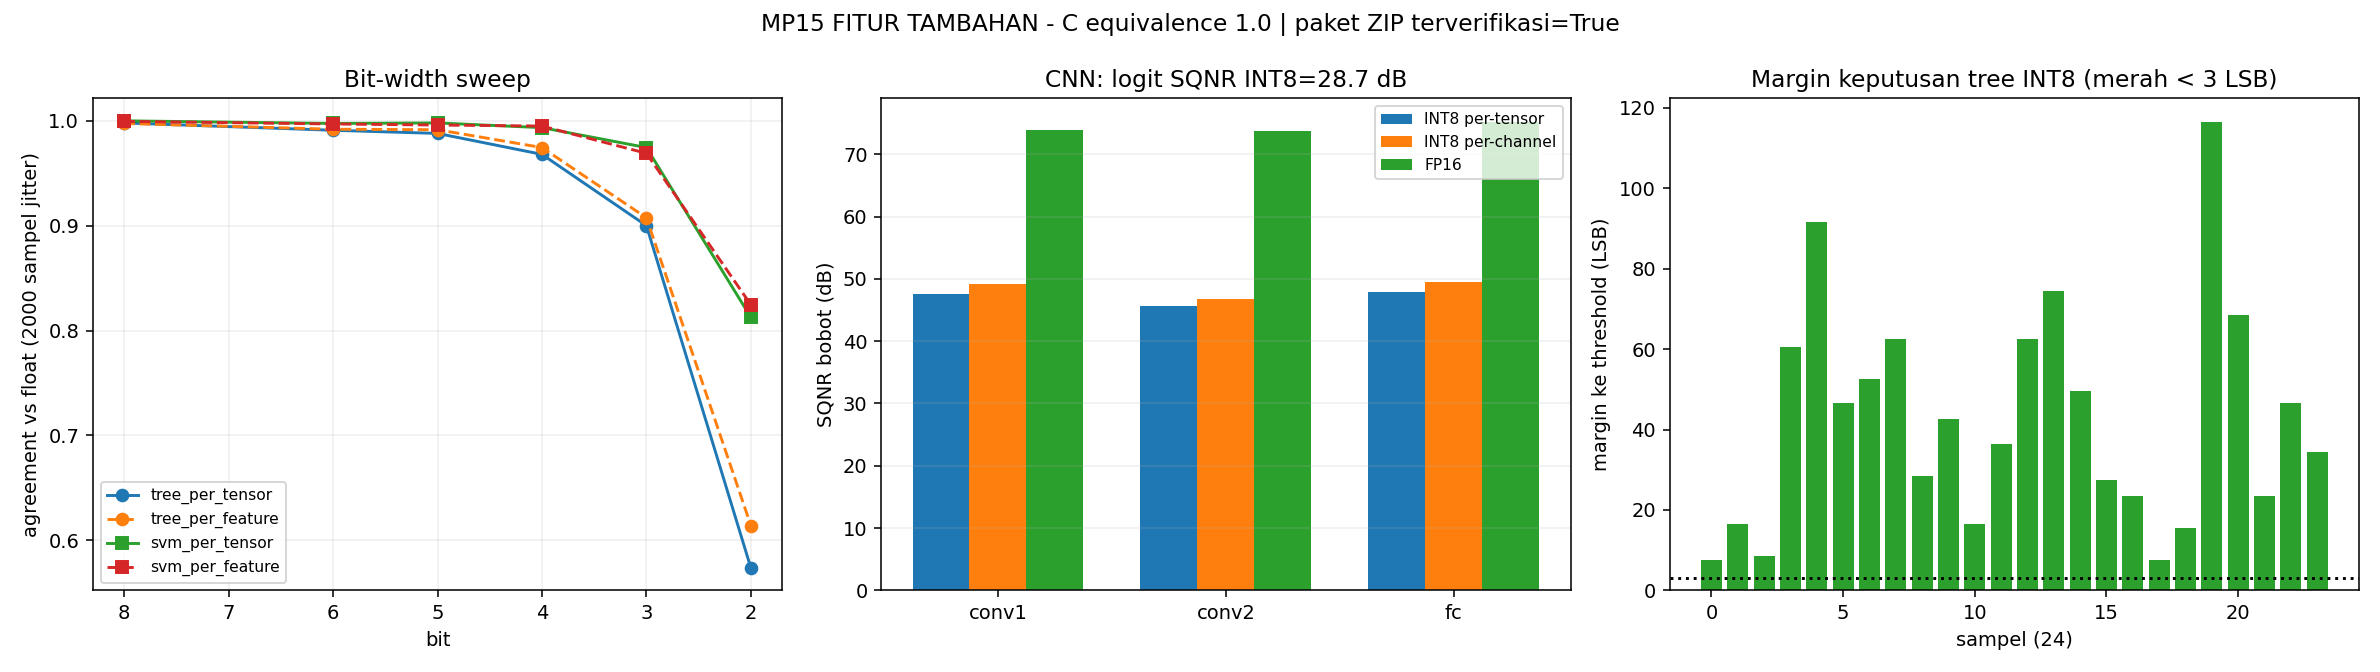

In [19]:
if "__file__" not in globals():
    from IPython.display import Image, display
    display(Image(filename=str(OUT_FIG/'mp15_extension_quantization_analysis.png'), width=1000))